# Chapter 20: Social Preferences, Fairness, Identity, and Reciprocity

This notebook reruns four worked examples from the chapter: an envious responder in an ultimatum game (inequity aversion), the trust game, a gift wage, and conditional cooperation in a public-goods game. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def fehr_schmidt_utility(own, other, alpha, beta=0.0):
    """inequity-aversion: U = own - alpha max(other - own, 0) - beta max(own - other, 0).

    Book (ch020): own 4, other 16, alpha 0.5 gives -2; own 7, other 13 gives 4.
    """
    return own - alpha * max(other - own, 0.0) - beta * max(own - other, 0.0)


def ultimatum_min_offer(pie, alpha):
    """inequity-aversion: smallest offer s with s - alpha[(pie - s) - s] >= 0, s* = alpha pie / (1 + 2 alpha).

    Book (ch020): pie 20, alpha 0.5 gives 5.
    """
    return alpha * pie / (1 + 2 * alpha)


def conditional_contribution(belief, a, k, cap=20.0):
    """conditional-cooperation: g = a + k belief, kept within [0, cap].

    Book (ch020): 2 + 0.6(15) = 11; 2 + 0.6(5) = 5.
    """
    return min(max(a + k * belief, 0.0), cap)


plt.rcParams.update(HOUSE_RC)


behavioral = SimpleNamespace(fehr_schmidt_utility=fehr_schmidt_utility, ultimatum_min_offer=ultimatum_min_offer, conditional_contribution=conditional_contribution)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'inequity-aversion': {'pie': 20,
                       'offer': 4,
                       'alpha': 0.5,
                       'u_accept': -2,
                       'offer_2': 7,
                       'u_accept_2': 4,
                       'min_offer': 5},
 'trust-game-reciprocity': {'E': 12,
                            'm': 3,
                            's': 6,
                            'r': 8,
                            'pi1': 14,
                            'pi2': 10,
                            'total': 24,
                            'total_selfish': 12,
                            'chance_return': 3,
                            'reciprocity_extra': 5},
 'gift-exchange-efficiency-wage': {'w0': 18,
                                   'w1': 22,
                                   'v': 6,
                                   'e0': 8,
                                   'e1': 10,
                                   'e1_alt': 8.5,
                                   'revenue0': 48,
                                   'profit0': 30,
                                   'revenue1': 60,
                                   'profit1': 38,
                                   'revenue_alt': 51,
                                   'profit_alt': 29},
 'conditional-cooperation': {'endowment': 20,
                             'mpcr': 0.4,
                             'n': 4,
                             'a': 2,
                             'k': 0.6,
                             'belief': 15,
                             'g': 11,
                             'net_cost': 6.6,
                             'group_benefit': 17.6,
                             'belief_2': 5,
                             'g_2': 5,
                             'fixed_point': 5,
                             'per_token_benefit': 1.6},
 'constructed': {'inequity-aversion': {'alpha': [0, 0.25, 1], 'offer': [5]},
                 'trust-game-reciprocity': {'s': [3, 12], 'return_share': ['1/3']},
                 'gift-exchange-efficiency-wage': {'e1': [9], 'v': [4, 8]},
                 'conditional-cooperation': {'belief': [10, 20], 'k': [0, 0.9]}}}


def trust_payoffs(E, m, s, r):
    """trust-game-reciprocity: sender E - s + r, receiver m s - r, total E + (m - 1) s."""
    return {"pi1": E - s + r, "pi2": m * s - r, "total": E + (m - 1) * s}


def gift_profit(effort, value, wage):
    """gift-exchange-efficiency-wage: profit = value x effort - wage."""
    return value * effort - wage


def fixed_point(a, k, cap):
    """conditional-cooperation: symmetric g = a + k g, so g = a / (1 - k), capped."""
    return cap if k >= 1 else min(a / (1 - k), cap)


def whole(x):
    """Number without decimals when whole, else two decimals."""
    return num(x, 0) if abs(x - round(x)) < 1e-9 else num(x)


def envy_picture(alpha=0.5, s=4):
    pie = BV["inequity-aversion"]["pie"]
    u = behavioral.fehr_schmidt_utility(s, pie - s, alpha)
    smin = behavioral.ultimatum_min_offer(pie, alpha)
    smin_whole = int(np.ceil(smin - 1e-9))
    who, tie = tie_or_winner("accept", u, "reject", 0.0)
    fig, ax = new_figure()
    grid = np.linspace(0, 10, 201)
    ax.plot(grid, [behavioral.fehr_schmidt_utility(x, pie - x, alpha) for x in grid], color=PALETTE["navy"],
            linewidth=2.2)
    if smin > 0:
        ax.axvspan(0, smin, color=PALETTE["terracotta"], alpha=0.12)
        label(ax, smin / 2, 8.5, "rejected offers", col="terracotta", dx=0, dy=0, ha="center")
    hline(ax, 0, "reject: 0 for both", col="grey", x_frac=0.74)
    vline(ax, smin, f"s* = {num(smin)}", col="terracotta", y_frac=0.97)
    mark(ax, s, u, f"offer {s}: U = {num(u)}", col="gold", dx=-8, dy=10 if u >= 0 else -10, ha="right",
         va="bottom" if u >= 0 else "top")
    ax.set_xlim(0, 10)
    ax.set_ylim(-12, 11)
    ax.set_xlabel("Offer to responder s ($ of 20)")
    ax.set_ylabel("Responder utility of accepting")
    if tie:
        verdict = "The responder is exactly indifferent; acceptance is weakly preferred, so the offer just succeeds"
    elif who == "accept":
        verdict = "Accepting beats the zero from rejection, so the responder accepts"
    else:
        verdict = "Accepting is worse than the zero from rejection, so the responder rejects"
    decision = "Indifferent (accepts weakly)" if tie else ("Accept" if who == "accept" else "Reject")
    metrics = {"Proposer keeps ($)": num(pie - s, 0), "U of accepting": num(u), "U of rejecting": "0.00",
               "Minimum acceptable offer s*": num(smin), "Smallest whole-dollar offer": money(smin_whole, 0),
               "Decision": decision}
    interp = (f"U = {s} - {num(alpha)} x ({pie - s} - {s}) = {s} - {num(alpha * (pie - 2 * s))} = {num(u)}. "
              f"{verdict}. The threshold solves s - {num(alpha)}(20 - 2s) = 0, so s* = {num(alpha)} x 20 / "
              f"(1 + 2 x {num(alpha)}) = {num(alpha * pie)} / {num(1 + 2 * alpha)} = {num(smin)}.")
    steps = [f"Proposer keeps 20 - {s} = {pie - s}",
             f"Disadvantage = {pie - s} - {s} = {pie - 2 * s}",
             f"U = {s} - {num(alpha)} x {pie - 2 * s} = {num(u)}",
             f"s* = {num(alpha * pie)} / {num(1 + 2 * alpha)} = {num(smin)}, so offers of {money(smin_whole, 0)} or more are accepted",
             f"Decision: {decision.lower()}"]
    alt = (f"Responder utility of accepting rises with the offer. With envy weight {num(alpha)} it crosses zero at "
           f"s* = {num(smin)}; the offer of {s} gives utility {num(u)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


SHARES = {"0": 0.0, "1/3": 1 / 3, "4/9": 4 / 9}


def trust_picture(s=6, share="4/9"):
    b = BV["trust-game-reciprocity"]
    E, m = b["E"], b["m"]
    frac = SHARES[share]
    r = frac * m * s
    p = trust_payoffs(E, m, s, r)
    who, tie = tie_or_winner("trusting", p["pi1"], "keeping", E)
    fig, ax = new_figure()
    names = ["No trust (send 0)", f"Send {s}"]
    stacked_bar(ax, names, [[E, p["pi1"]], [0, p["pi2"]]], ["sender", "receiver"],
                colors=["navy", "teal"], ylabel="Payoff ($)", fmt=lambda t: whole(t))
    hline(ax, E, col="terracotta")
    ax.text(0.98, 0.97, f"dashed line: sender keeps {E} without trust. Net = total payoff", transform=ax.transAxes, ha="right", va="top",
            fontsize=10.5, color=PALETTE["terracotta"])
    ax.set_ylim(0, 52)
    ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.9), frameon=False)
    ax.set_xlabel("Sender's choice")
    if s == 0:
        verdict = "Nothing is sent, so nothing is multiplied and the sender keeps 12"
    elif tie:
        verdict = "The sender exactly breaks even: trusting neither gains nor loses against keeping 12"
    elif who == "trusting":
        verdict = f"Trusting pays the sender {whole(p['pi1'] - E)} more than keeping the 12"
    else:
        verdict = f"Trusting costs the sender {whole(E - p['pi1'])} against keeping the 12"
    metrics = {"Receiver gets ($)": whole(m * s), "Returned r ($)": whole(r), "Sender payoff pi1 ($)": whole(p["pi1"]),
               "Receiver payoff pi2 ($)": whole(p["pi2"]), "Total payoff ($)": whole(p["total"]),
               "Sender vs no trust": "break even" if (tie or s == 0) else ("gains" if who == "trusting" else "loses")}
    interp = (f"The receiver gets 3 x {s} = {whole(m * s)} and returns {share} of it, r = {whole(r)}. "
              f"pi1 = 12 - {s} + {whole(r)} = {whole(p['pi1'])} and pi2 = {whole(m * s)} - {whole(r)} = "
              f"{whole(p['pi2'])}, a total of {whole(p['total'])}. {verdict}.")
    steps = [f"Receiver gets 3 x {s} = {whole(m * s)}",
             f"r = {share} x {whole(m * s)} = {whole(r)}",
             f"pi1 = 12 - {s} + {whole(r)} = {whole(p['pi1'])}",
             f"pi2 = {whole(m * s)} - {whole(r)} = {whole(p['pi2'])}",
             f"Total = 12 + 2 x {s} = {whole(p['total'])}"]
    alt = (f"Stacked payoff bars. Without trust the sender has 12 and the receiver 0. Sending {s} with {share} "
           f"returned gives the sender {whole(p['pi1'])} and the receiver {whole(p['pi2'])}, total {whole(p['total'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def gift_picture(e22=10, v=6):
    b = BV["gift-exchange-efficiency-wage"]
    w0, w1, e0 = b["w0"], b["w1"], b["e0"]
    p0, p1 = gift_profit(e0, v, w0), gift_profit(e22, v, w1)
    be = e0 + (w1 - w0) / v
    who, tie = tie_or_winner("gift", p1, "base", p0)
    fig, ax = new_figure()
    bar_compare(ax, [f"Wage $18, effort 8", f"Wage $22, effort {whole(e22)}"], [p0, p1],
                colors=["navy", "teal" if p1 >= p0 else "terracotta"],
                value_labels=[f"profit {money(p0)}", f"profit {money(p1)}"], ylabel="Profit per hour ($)",
                xlabel="Wage offer")
    hline(ax, p0, col="grey")
    ax.set_ylim(0, 72)
    ax.text(0.98, 0.97, tex_safe(f"dashed line: profit at $18. Break-even effort at $22: {num(be)} units"), transform=ax.transAxes, ha="right", va="top",
            fontsize=10.5, color=PALETTE["ink"])
    if tie:
        verdict = "The two profits are equal: the premium exactly pays for itself"
    elif who == "gift":
        verdict = f"The gift wage raises profit by {money(p1 - p0)}"
    else:
        verdict = f"The gift wage lowers profit by {money(p0 - p1)}"
    metrics = {"Profit at $18": money(p0), "Profit at $22": money(p1), "Change in profit": money(p1 - p0),
               "Break-even effort at $22": num(be), "Gift wage": "tie" if tie else ("pays" if who == "gift" else "does not pay")}
    interp = (f"At $18: {v} x 8 - 18 = {num(v * e0, 0)} - 18 = {money(p0)}. At $22: {v} x {whole(e22)} - 22 = "
              f"{whole(v * e22)} - 22 = {money(p1)}. {verdict}. The premium pays when {v}(e - 8) > 4, that is "
              f"e > 8 + 4/{v} = {num(be)}.")
    steps = [f"Profit at $18 = {v} x 8 - 18 = {money(p0)}",
             f"Profit at $22 = {v} x {whole(e22)} - 22 = {money(p1)}",
             f"Extra output value = {v} x ({whole(e22)} - 8) = {whole(v * (e22 - e0))}, against a $4 premium",
             f"Break-even effort = 8 + 4 / {v} = {num(be)}"]
    alt = (f"Two profit bars: {money(p0)} at the $18 wage and {money(p1)} at the $22 wage with effort {whole(e22)} "
           f"and value {v} per unit.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cooperation_picture(b=15, k=0.6):
    bv = BV["conditional-cooperation"]
    a, cap, mpcr, n = bv["a"], bv["endowment"], bv["mpcr"], bv["n"]
    g = behavioral.conditional_contribution(b, a, k, cap)
    fp = fixed_point(a, k, cap)
    raw = a + k * b
    fig, ax = new_figure()
    xs = np.linspace(0, 20, 201)
    ax.plot(xs, [behavioral.conditional_contribution(x, a, k, cap) for x in xs], color=PALETTE["navy"], linewidth=2.2,
            label=f"response g = 2 + {num(k, 1)} x belief")
    ax.plot(xs, xs, color=PALETTE["grey"], linestyle="dashed", linewidth=1.4, label="45 degree line")
    ax.legend(loc="upper left", frameon=False)
    right = fp > 12
    same = abs(b - fp) < 1e-9 and abs(g - fp) < 1e-9
    near = abs(g - fp) < 3 and abs(b - fp) < 6
    mark(ax, fp, fp, None if same else f"fixed point {num(fp)}", col="terracotta", dx=-8 if right else 8,
         dy=32 if near else 10, ha="right" if right else "left")
    low = g < 6
    mark(ax, b, g, f"belief {b}: g = {num(g)}" + (", the fixed point" if same else ""), col="gold", dx=-8 if b >= 15 else 8, dy=10 if low else -10,
         ha="right" if b >= 15 else "left", va="bottom" if low else "top")
    ax.set_xlim(0, 21)
    ax.set_ylim(0, 25)
    ax.set_xlabel("Belief about others' average contribution (tokens)")
    ax.set_ylabel("Own contribution g (tokens)")
    metrics = {"Contribution g": num(g), "Private net cost g(1 - 0.4)": num(g * (1 - mpcr)),
               "Group benefit 1.6 g": num(g * n * mpcr), "Symmetric fixed point": num(fp)}
    capped = raw > cap + 1e-9
    calc = f"g = 2 + {num(k, 1)} x {b} = {num(raw)}" + (f", capped at {cap}" if capped else "")
    fp_text = (f"g = 2 + {num(k, 1)}g gives g = 2 / {num(1 - k, 1)} = {num(a / (1 - k))}"
               + (f", above the cap, so contributions settle at {cap}" if a / (1 - k) > cap + 1e-9
                  else (f", exactly the cap of {cap}" if abs(a / (1 - k) - cap) < 1e-9 else "")))
    interp = (f"{calc}. Her private net cost is {num(g)} x 0.6 = {num(g * (1 - mpcr))} tokens and the group gains "
              f"{num(g)} x 1.6 = {num(g * n * mpcr)}. If all four share the schedule, {fp_text}.")
    steps = [calc, f"Net cost = {num(g)} x 0.6 = {num(g * (1 - mpcr))}",
             f"Group benefit = {num(g)} x 1.6 = {num(g * n * mpcr)}", f"Fixed point: {fp_text}"]
    alt = (f"Response line g = 2 + {num(k, 1)} x belief against the 45 degree line. At belief {b} the contribution "
           f"is {num(g)}; the line meets the 45 degree line at {num(fp)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Inequity aversion: how much envy forces a fair offer

A proposer splits \$20 and offers \$4. The responder's envy weight is $\alpha=0.5$; rejecting gives both zero. Accepting gives

$$U_R=4-0.5(16-4)=-2.$$

and an offer $s$ is accepted when

$$s-0.5[(20-s)-s]\geq0.$$

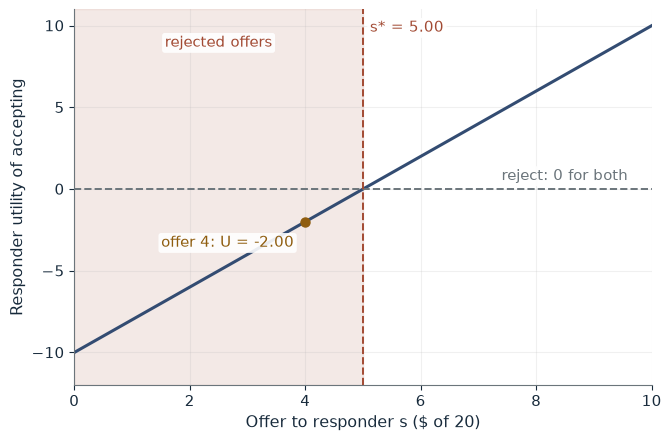

Proposer keeps ($)           16
U of accepting               -2.00
U of rejecting               0.00
Minimum acceptable offer s*  5.00
Smallest whole-dollar offer  $5
Decision                     Reject

Worked steps:
  1. Proposer keeps 20 - 4 = 16
  2. Disadvantage = 16 - 4 = 12
  3. U = 4 - 0.50 x 12 = -2.00
  4. s* = 10.00 / 2.00 = 5.00, so offers of $5 or more are accepted
  5. Decision: reject

U = 4 - 0.50 x (16 - 4) = 4 - 6.00 = -2.00. Accepting is worse than the zero from rejection, so the responder rejects. The threshold solves s - 0.50(20 - 2s) = 0, so s* = 0.50 x 20 / (1 + 2 x 0.50) = 10.00 / 2.00 = 5.00.


In [2]:
show(envy_picture(alpha=0.5, s=4))

Change one input, `alpha`, and hold the others at the book's values:

In [3]:
sweep(envy_picture, 'alpha', [0, 0.25, 0.5, 1], {'s': 4}, ['U of accepting', 'Minimum acceptable offer s*', 'Decision'])

alpha | U of accepting | Minimum acceptable offer s* | Decision
0 | 4.00 | 0.00 | Accept
0.25 | 1.00 | 3.33 | Accept
0.5 | -2.00 | 5.00 | Reject
1 | -8.00 | 6.67 | Reject


The \$4 offer is rejected: the responder gives up \$4 to remove a \$12 disadvantage. The threshold is $s^*=\alpha \cdot 20/(1+2\alpha)=5$; at exactly \$5 the responder is indifferent and accepts weakly, and at \$7 utility is 4.

## 2. Trust-game reciprocity: trust game surplus

The sender holds \$12 and sends \$6, which is tripled to \$18; the receiver returns \$8 (4/9 of 18).

$$\pi_1=12-6+8=\$14, \qquad \pi_2=18-8=\$10.$$

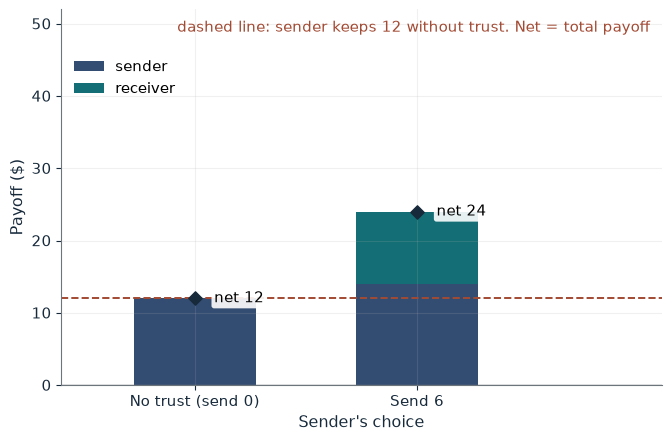

Receiver gets ($)        18
Returned r ($)           8
Sender payoff pi1 ($)    14
Receiver payoff pi2 ($)  10
Total payoff ($)         24
Sender vs no trust       gains

Worked steps:
  1. Receiver gets 3 x 6 = 18
  2. r = 4/9 x 18 = 8
  3. pi1 = 12 - 6 + 8 = 14
  4. pi2 = 18 - 8 = 10
  5. Total = 12 + 2 x 6 = 24

The receiver gets 3 x 6 = 18 and returns 4/9 of it, r = 8. pi1 = 12 - 6 + 8 = 14 and pi2 = 18 - 8 = 10, a total of 24. Trusting pays the sender 2 more than keeping the 12.


In [4]:
show(trust_picture(s=6, share='4/9'))

Change one input, `s`, and hold the others at the book's values:

In [5]:
sweep(trust_picture, 's', [0, 3, 6, 12], {'share': '4/9'}, ['Sender payoff pi1 ($)', 'Receiver payoff pi2 ($)', 'Total payoff ($)'])

s | Sender payoff pi1 ($) | Receiver payoff pi2 ($) | Total payoff ($)
0 | 12 | 0 | 12
3 | 13 | 5 | 18
6 | 14 | 10 | 24
12 | 16 | 20 | 36


Total payoff rises from 12 to 24 because each dollar sent becomes three. The sender gains only when the return exceeds the amount sent; a one-third return leaves her exactly at 12.

## 3. Gift-exchange efficiency wage: when a gift wage pays for itself

At the customary \$18 wage a worker handles 8 units worth \$6 each; at \$22 she handles 10.

$$8(\$6)=\$48, \qquad \$60-\$22=\$38.$$

The premium pays when

$$\$6[e(22)-e(18)]>\$4.$$

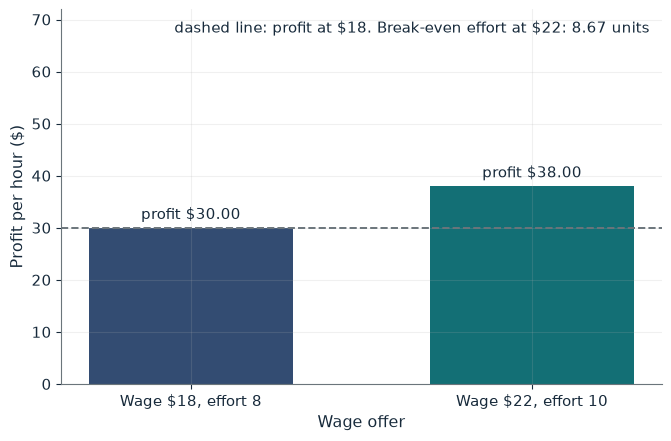

Profit at $18             $30.00
Profit at $22             $38.00
Change in profit          $8.00
Break-even effort at $22  8.67
Gift wage                 pays

Worked steps:
  1. Profit at $18 = 6 x 8 - 18 = $30.00
  2. Profit at $22 = 6 x 10 - 22 = $38.00
  3. Extra output value = 6 x (10 - 8) = 12, against a $4 premium
  4. Break-even effort = 8 + 4 / 6 = 8.67

At $18: 6 x 8 - 18 = 48 - 18 = $30.00. At $22: 6 x 10 - 22 = 60 - 22 = $38.00. The gift wage raises profit by $8.00. The premium pays when 6(e - 8) > 4, that is e > 8 + 4/6 = 8.67.


In [6]:
show(gift_picture(e22=10, v=6))

Change one input, `e22`, and hold the others at the book's values:

In [7]:
sweep(gift_picture, 'e22', [8.5, 9, 10], {'v': 6}, ['Profit at $18', 'Profit at $22', 'Change in profit'])

e22 | Profit at $18 | Profit at $22 | Change in profit
8.5 | $30.00 | $29.00 | -$1.00
9 | $30.00 | $32.00 | $2.00
10 | $30.00 | $38.00 | $8.00


Profit rises from \$30 to \$38 at 10 units, but falls to \$29 if effort reaches only 8.5. The break-even effort is $8+4/6=8.67$ units.

## 4. Conditional cooperation: the fixed point

Four tenants hold 20 tokens; each token returns 0.4 to every tenant, so $4(0.4)=1.6>1$. Lina contributes

$$g_L=2+0.6E_L(\bar g_{-L}),$$

capped at 20. If all share the schedule, $g=2+0.6g$ gives $g=5$.

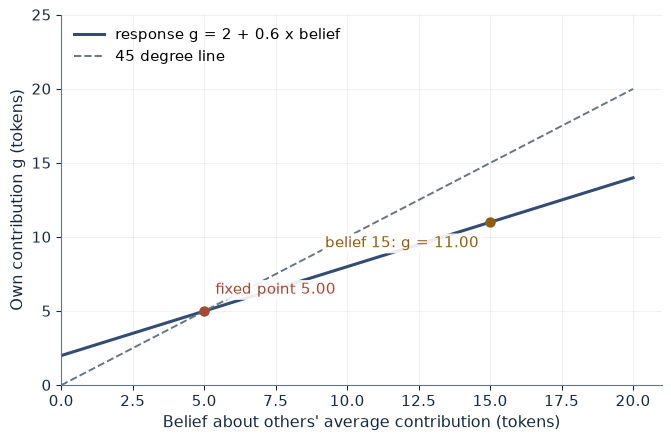

Contribution g               11.00
Private net cost g(1 - 0.4)  6.60
Group benefit 1.6 g          17.60
Symmetric fixed point        5.00

Worked steps:
  1. g = 2 + 0.6 x 15 = 11.00
  2. Net cost = 11.00 x 0.6 = 6.60
  3. Group benefit = 11.00 x 1.6 = 17.60
  4. Fixed point: g = 2 + 0.6g gives g = 2 / 0.4 = 5.00

g = 2 + 0.6 x 15 = 11.00. Her private net cost is 11.00 x 0.6 = 6.60 tokens and the group gains 11.00 x 1.6 = 17.60. If all four share the schedule, g = 2 + 0.6g gives g = 2 / 0.4 = 5.00.


In [8]:
show(cooperation_picture(b=15, k=0.6))

Change one input, `b`, and hold the others at the book's values:

In [9]:
sweep(cooperation_picture, 'b', [5, 10, 15, 20], {'k': 0.6}, ['Contribution g', 'Private net cost g(1 - 0.4)', 'Group benefit 1.6 g'])

b | Contribution g | Private net cost g(1 - 0.4) | Group benefit 1.6 g
5 | 5.00 | 3.00 | 8.00
10 | 8.00 | 4.80 | 12.80
15 | 11.00 | 6.60 | 17.60
20 | 14.00 | 8.40 | 22.40


Expecting 15, Lina gives 11 at a private cost of 6.6 tokens and a group benefit of 17.6. Beliefs above 5 produce contributions below them, so feedback pulls the group down to the fixed point 5.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

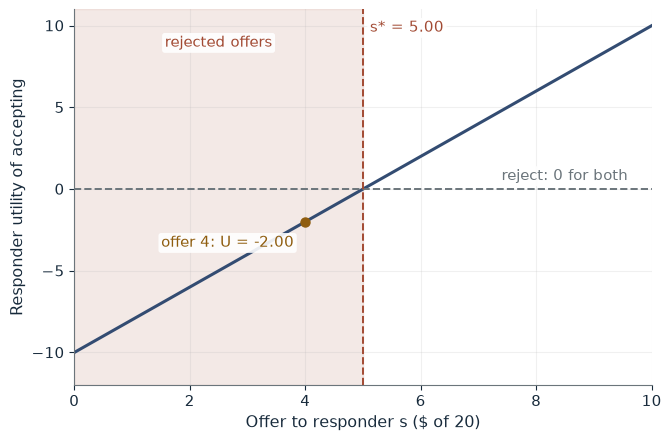

Proposer keeps ($)           16
U of accepting               -2.00
U of rejecting               0.00
Minimum acceptable offer s*  5.00
Smallest whole-dollar offer  $5
Decision                     Reject

Worked steps:
  1. Proposer keeps 20 - 4 = 16
  2. Disadvantage = 16 - 4 = 12
  3. U = 4 - 0.50 x 12 = -2.00
  4. s* = 10.00 / 2.00 = 5.00, so offers of $5 or more are accepted
  5. Decision: reject

U = 4 - 0.50 x (16 - 4) = 4 - 6.00 = -2.00. Accepting is worse than the zero from rejection, so the responder rejects. The threshold solves s - 0.50(20 - 2s) = 0, so s* = 0.50 x 20 / (1 + 2 x 0.50) = 10.00 / 2.00 = 5.00.


In [10]:
show(envy_picture(alpha=0.5, s=4))

## Practice

**1.** With alpha = 1, what is the smallest acceptable offer out of \$20?

<details><summary>Answer</summary>

s - 1(20 - 2s) >= 0 gives 3s >= 20, s >= 6.67, so \$7 in whole dollars.

</details>

**2.** In the trust game, the sender sends \$6 and the receiver returns one third of the \$18. Does trust pay?

<details><summary>Answer</summary>

r = 18/3 = 6, so pi1 = 12 - 6 + 6 = 12: exactly break even. The total is still 12 + 2 x 6 = 24.

</details>

**3.** With slope 0.9 and intercept 2, where do symmetric contributions settle?

<details><summary>Answer</summary>

g = 2 + 0.9g gives g = 2 / 0.1 = 20, which is the cap.

</details>